<a href="https://colab.research.google.com/github/Bimo-Hadi/BUCI_Detection/blob/main/Beeonic_Final_Model_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RS Beeonic Breast Ultrasound AI v2: Multi-task Attention U-Net + Ensemble + API
**ASBE UI Mini Study Case Competition 2026**. Builds on the Day 2 notebook, the v1 transfer-learning notebook and the Attention U-Net segmentation notebook.

**How to run:** `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`. Needs internet (dataset + pretrained weights).

### What is new in v2
| Idea | Why it should help |
|---|---|
| **Multi-task model**: one EfficientNet-B0 encoder, a **classification head** and an **Attention U-Net decoder** that segments the lesion | The BUSI lesion masks (training data only) teach the encoder *where the lesion is*, which regularises the classifier on only 546 training images and gives better Grad-CAM |
| **Ensemble** of several seeds + flip TTA | Averages out seed noise on a small data set |
| Decision threshold fixed on **validation** | Controls malignant false alarms (the reason the last vendor failed) |
| **FastAPI service** (section 11) | Lets the hospital PACS / worklist call the model, with API key, batch worklist sorting and on-premise deployment |

### Evidence rules (honesty), please read
* Split is **identical** to Day 2 (70/15/15, stratified, seed 42). Test is touched **once** (section 8).
* **Ground-truth masks are used only as a training target, never as an input.** If masks were fed to the model at test time, "normal" would be trivially identified by an empty mask and accuracy would look like 99%+. That would be leakage, not a result.
* We do **not** target or promise 99.9%. On 117 test images with only 31 malignant, such a number would mostly signal leakage or luck. The SOP asks for 0.70 preferred; the confidence intervals in section 8 show how uncertain any number is.

## 1. Configuration

In [ ]:
import os, sys, json, random, hashlib, shutil, subprocess, zipfile, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# ---------------- Main settings ----------------
SPLIT_SEED   = 42            # same as Day 2, so the split is identical
MODEL_SEEDS  = [42, 7, 123]  # one model per seed; predictions are averaged
N_MODELS     = 3             # ensemble size (decided in advance, not tuned on test)
IMG_SIZE     = 224
BATCH_SIZE   = 16
PRETRAINED   = True          # ImageNet weights (needs internet). False = random init (debug only)
QUICK_TEST   = False         # True = tiny dry run to check the code path (results meaningless)

EPOCHS_HEAD  = 20            # stage 1: backbone frozen (head + decoder learn)
EPOCHS_FT    = 40            # stage 2: fine-tune top backbone layers
FT_LAYERS    = 60            # how many top backbone layers to unfreeze (BatchNorm stays frozen)
LR_HEAD      = 1e-3
LR_FT        = 3e-5
SEG_WEIGHT   = 0.5           # weight of the segmentation loss relative to classification
USE_TTA      = True          # average prediction of image and horizontal flip
MODEL_VERSION = '2.0'

CLASS_NAMES  = ['benign', 'malignant', 'normal']   # same label order as Day 2
MAL          = CLASS_NAMES.index('malignant')
KAGGLE_SLUG  = 'aryashah2k/breast-ultrasound-images-dataset'
OUT_DIR      = 'outputs'
PKG_DIR      = f'{OUT_DIR}/beeonic_api'              # self-contained API package (code + models)
os.makedirs(f'{PKG_DIR}/models', exist_ok=True)

if QUICK_TEST:
    EPOCHS_HEAD, EPOCHS_FT, N_MODELS = 2, 2, 2
MODEL_SEEDS = MODEL_SEEDS[:N_MODELS]

# ---------------- Hospital SOP-RAD-AI-01 targets ----------------
SOP = {   # metric: (mandatory, preferred)
    'accuracy':      (0.62, 0.70),
    'mal_recall':    (0.60, 0.70),
    'macro_f1':      (0.58, 0.65),
    'mal_precision': (None, 0.70),   # mandatory = report only
}
# Day 2 baseline: copied from the Day 2 notebook's own test output
BASELINE = {'accuracy': 0.598, 'mal_recall': 0.548, 'macro_f1': 0.546, 'mal_precision': 0.607}
METRIC_LABELS = {'accuracy': 'Accuracy', 'mal_recall': 'Malignant recall',
                 'macro_f1': 'Macro F1', 'mal_precision': 'Malignant precision'}
# Proposed pilot triage targets (NOT hospital policy); used by the API
TRIAGE = {
    'malignant': {'priority': 'URGENT',   'suggested_read_within': '1 day'},
    'benign':    {'priority': 'ROUTINE',  'suggested_read_within': '2-3 days'},
    'normal':    {'priority': 'STANDARD', 'suggested_read_within': '5 days'},
}

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
import tensorflow as tf
import keras
from keras import layers

random.seed(SPLIT_SEED); np.random.seed(SPLIT_SEED); keras.utils.set_random_seed(SPLIT_SEED)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'none (CPU mode, slower)')

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data: images + lesion masks, split identical to Day 2, leakage check

In [ ]:
def find_busi_root(search_dirs):
    seen = set()
    for start in search_dirs:
        start = os.path.realpath(start)
        if start in seen or not os.path.isdir(start):
            continue
        seen.add(start)
        for dp, dn, fn in os.walk(start):
            if os.path.basename(dp) == 'Dataset_BUSI_with_GT' and all(c in dn for c in CLASS_NAMES):
                return dp
    return None

def pip_install(pkg):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

def download_busi():
    # Try kagglehub first, then the Kaggle CLI. Returns a folder that contains the dataset.
    try:
        pip_install('kagglehub'); import kagglehub
        return kagglehub.dataset_download(KAGGLE_SLUG)
    except Exception as e:
        print('kagglehub failed:', repr(e)[:150])
    try:
        pip_install('kaggle')
        subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_SLUG], check=True)
        with zipfile.ZipFile('breast-ultrasound-images-dataset.zip') as z:
            z.extractall('breast-ultrasound-images-dataset')
        return 'breast-ultrasound-images-dataset'
    except Exception as e:
        print('kaggle CLI failed:', repr(e)[:150])
    return None

base_dir = find_busi_root(['.', '/content', '/kaggle/input'])
if base_dir is None:
    got = download_busi()
    base_dir = find_busi_root([got]) if got else None
if base_dir is None:
    raise RuntimeError(
        'Dataset not found and the automatic download failed. Fix: download the zip from '
        'https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset , upload it to Colab '
        '(left sidebar > Files), run: !unzip -q breast-ultrasound-images-dataset.zip -d breast-ultrasound-images-dataset  '
        'then run this cell again.')
print('Dataset folder:', base_dir)

# Same image listing as Day 2: sorted, segmentation masks excluded
records = []
for label in CLASS_NAMES:
    for f in sorted(Path(base_dir, label).glob('*.png')):
        if '_mask' not in f.stem.lower():
            records.append({'path': str(f), 'label': label})
df = pd.DataFrame(records)
assert len(df) > 0, 'No images found'
print('Total images:', len(df)); print(df['label'].value_counts().reindex(CLASS_NAMES))

Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
Dataset folder: /kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT
Total images: 780
label
benign       437
malignant    210
normal       133
Name: count, dtype: int64


In [ ]:
# Split: 70% train / 15% validation / 15% test, stratified, seed 42 (identical to Day 2)
train_df, other_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SPLIT_SEED)
val_df, test_df    = train_test_split(other_df, test_size=0.50, stratify=other_df['label'], random_state=SPLIT_SEED)

split_table = pd.DataFrame({n: d['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
                            for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]})
split_table.loc['total'] = split_table.sum(); display(split_table)

label_to_id = {n: i for i, n in enumerate(CLASS_NAMES)}

def load_lesion_mask(img_path):
    # Merge all masks of one image (x_mask.png, x_mask_1.png, ...) into one binary mask (training target only)
    p = Path(img_path); m = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for mp in sorted(p.parent.glob(p.stem + '_mask*.png')):
        with Image.open(mp) as im:
            a = np.asarray(im.convert('L').resize((IMG_SIZE, IMG_SIZE), Image.NEAREST))
        m = np.maximum(m, (a > 127).astype(np.uint8))
    return m

def load_data(frame):
    n = len(frame)
    X = np.zeros((n, IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)    # grayscale
    M = np.zeros((n, IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)    # lesion mask (0/1)
    for i, p in enumerate(frame['path']):
        with Image.open(p) as im:
            X[i, :, :, 0] = np.asarray(im.convert('L').resize((IMG_SIZE, IMG_SIZE)), dtype=np.uint8)
        M[i, :, :, 0] = load_lesion_mask(p)
    return X, M, frame['label'].map(label_to_id).to_numpy(dtype=np.int32)

x_train, m_train, y_train = load_data(train_df)
x_val,   m_val,   y_val   = load_data(val_df)
x_test,  m_test,  y_test  = load_data(test_df)
print('train', x_train.shape, '| val', x_val.shape, '| test', x_test.shape)
print('Share of normal images with an empty mask (train):', round(float((m_train[y_train == 2].sum((1, 2, 3)) == 0).mean()), 3),
      '<- this is why masks must never be a model INPUT')

# Leakage check: exact duplicate images across splits
h = lambda X: [hashlib.md5(a.tobytes()).hexdigest() for a in X]
htr, hva, hte = set(h(x_train)), set(h(x_val)), set(h(x_test))
print(f'Exact duplicates  train&test: {len(htr & hte)} | train&val: {len(htr & hva)} | val&test: {len(hva & hte)}')
print('Note: BUSI may hold near-duplicates / several images per patient; no patient IDs, so the split is image-level.')

,train,val,test
label,,,
benign,306,65,66
malignant,147,32,31
normal,93,20,20
total,546,117,117


train (546, 224, 224, 1) | val (117, 224, 224, 1) | test (117, 224, 224, 1)
Share of normal images with an empty mask (train): 1.0 <- this is why masks must never be a model INPUT
Exact duplicates  train&test: 1 | train&val: 0 | val&test: 0
Note: BUSI may hold near-duplicates / several images per patient; no patient IDs, so the split is image-level.


## 3. Input pipeline: image and mask are augmented together
Geometric augmentations are applied to the image **and** its mask with the same random parameters (stacked as 4 channels). Brightness/contrast only touch the image. Only mild, ultrasound-safe changes.

Class weights: {'benign': 0.771, 'malignant': 1.113, 'normal': 1.399}


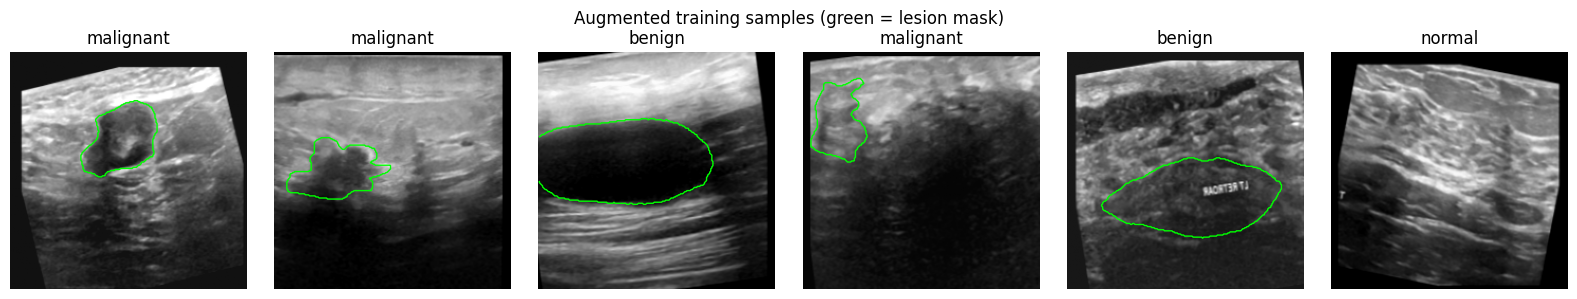

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

geo = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.04, fill_mode='constant'),        # about +/- 7 degrees
    layers.RandomZoom(0.10, fill_mode='constant'),
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant'),
], name='geo_aug')
photo = keras.Sequential([
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10, value_range=(0, 255)),
], name='photo_aug')

def to_rgb255(x):
    # EfficientNet in Keras expects raw 0..255 pixels and rescales internally
    return tf.repeat(tf.cast(x, tf.float32), 3, axis=-1)

# Class weights: softened 'balanced' (square root). Fixed in advance, not tuned on test.
bal = compute_class_weight('balanced', classes=np.arange(3), y=y_train)
cw_vec = tf.constant(np.sqrt(bal).astype(np.float32))
print('Class weights:', {n: round(float(w), 3) for n, w in zip(CLASS_NAMES, cw_vec.numpy())})

def make_train_ds(X, M, y, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, M, y)).shuffle(len(X), seed=seed, reshuffle_each_iteration=True).batch(BATCH_SIZE)
    def f(x, m, yy):
        z = tf.concat([to_rgb255(x), tf.cast(m, tf.float32) * 255.0], axis=-1)   # 4 channels: RGB + mask
        z = geo(z, training=True)
        img = tf.clip_by_value(photo(z[..., :3], training=True), 0.0, 255.0)
        msk = tf.cast(z[..., 3:] > 127.5, tf.float32)
        return img, {'probs': yy, 'seg': msk}
    return ds.map(f, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

def make_eval_ds(X, M, y):
    ds = tf.data.Dataset.from_tensor_slices((X, M, y)).batch(32)
    return ds.map(lambda x, m, yy: (to_rgb255(x), {'probs': yy, 'seg': tf.cast(m, tf.float32)}), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

val_ds = make_eval_ds(x_val, m_val, y_val)

# Visual check: augmented image + mask contour must stay aligned
xb, tb = next(iter(make_train_ds(x_train, m_train, y_train, 0)))
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, im, mk, lb in zip(axes, xb[:6].numpy(), tb['seg'][:6].numpy(), tb['probs'][:6].numpy()):
    ax.imshow(im[..., 0], cmap='gray', vmin=0, vmax=255)
    if mk.max() > 0: ax.contour(mk[..., 0], levels=[0.5], colors='lime', linewidths=1)
    ax.set_title(CLASS_NAMES[lb]); ax.axis('off')
plt.suptitle('Augmented training samples (green = lesion mask)'); plt.tight_layout()
os.makedirs(OUT_DIR, exist_ok=True); plt.savefig(f'{OUT_DIR}/augmentation_samples.png', dpi=130); plt.show()

## 4. Model: EfficientNet-B0 encoder + classification head + Attention U-Net decoder
The decoder reuses the idea of the Attention U-Net notebook: **attention gates** on the skip connections, so the decoder focuses on the lesion region. The classifier and the decoder share the encoder.

In [ ]:
SKIP_NAMES = ['block2a_expand_activation',   # 112x112
              'block3a_expand_activation',   # 56x56
              'block4a_expand_activation',   # 28x28
              'block6a_expand_activation']   # 14x14   (bottleneck = top_activation, 7x7)

def conv_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding='same', use_bias=False, name=f'{name}_conv{i}')(x)
        x = layers.BatchNormalization(name=f'{name}_bn{i}')(x)
        x = layers.Activation('relu', name=f'{name}_act{i}')(x)
    return x

def attention_gate(skip, gate, f, name):
    # Additive attention gate: the gate signal (decoder) decides which skip-connection pixels matter
    g = layers.Conv2D(f, 1, name=f'{name}_g')(gate)
    s = layers.Conv2D(f, 1, name=f'{name}_s')(skip)
    a = layers.Activation('relu', name=f'{name}_relu')(layers.Add(name=f'{name}_add')([g, s]))
    a = layers.Conv2D(1, 1, activation='sigmoid', name=f'{name}_psi')(a)
    return layers.Multiply(name=f'{name}_mul')([skip, a])

def build_model(seed):
    keras.utils.set_random_seed(seed)
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet' if PRETRAINED else None,
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    # ---- classification head
    x = layers.GlobalAveragePooling2D(name='gap')(base.output)
    x = layers.Dropout(0.3, name='drop')(x)
    logits = layers.Dense(len(CLASS_NAMES), name='logits')(x)
    probs = layers.Softmax(name='probs')(logits)
    # ---- Attention U-Net decoder on the encoder's skip features
    d = base.output
    for i, (sn, f) in enumerate(zip(SKIP_NAMES[::-1], [256, 128, 64, 32])):
        up = layers.UpSampling2D(name=f'dec{i}_up')(d)
        sk = attention_gate(base.get_layer(sn).output, up, f, f'att{i}')
        d = conv_block(layers.Concatenate(name=f'dec{i}_cat')([up, sk]), f, f'dec{i}')
    d = layers.UpSampling2D(name='seg_up')(d)
    seg = layers.Conv2D(1, 1, activation='sigmoid', name='seg')(d)
    model = keras.Model(base.input, {'probs': probs, 'seg': seg}, name=f'beeonic_mt_{seed}')
    return model, base

def weighted_sce(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    return keras.losses.sparse_categorical_crossentropy(y_true, y_pred) * tf.gather(cw_vec, y_true)

def dice_bce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    bce = tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred), axis=(1, 2))
    inter = tf.reduce_sum(y_true * y_pred, axis=(1, 2, 3))
    den = tf.reduce_sum(y_true, axis=(1, 2, 3)) + tf.reduce_sum(y_pred, axis=(1, 2, 3))
    return bce + (1.0 - (2.0 * inter + 1.0) / (den + 1.0))

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss={'probs': weighted_sce, 'seg': dice_bce},
                  loss_weights={'probs': 1.0, 'seg': SEG_WEIGHT},
                  metrics={'probs': ['accuracy']})

_m, _b = build_model(MODEL_SEEDS[0])
print('Params: {:,}  | skip layers found: {}'.format(_m.count_params(), all(_b.get_layer(n) is not None for n in SKIP_NAMES)))
del _m, _b

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Params: 10,699,371  | skip layers found: True


## 5. Metric helpers and decision rule

In [ ]:
def compute_metrics(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'mal_recall': r[MAL],
            'macro_f1': f.mean(), 'mal_precision': p[MAL]}

def predict_all(models, X, tta=USE_TTA):
    # Ensemble + optional flip-TTA. Returns class probabilities and lesion masks (both averaged).
    ds = tf.data.Dataset.from_tensor_slices(X).batch(32)
    P, S = [], []
    for m in models:
        o = m.predict(ds.map(to_rgb255), verbose=0); p, s = o['probs'], o['seg']
        if tta:
            o2 = m.predict(ds.map(lambda x: tf.image.flip_left_right(to_rgb255(x))), verbose=0)
            p = (p + o2['probs']) / 2.0; s = (s + o2['seg'][:, :, ::-1, :]) / 2.0
        P.append(p); S.append(s)
    return np.mean(P, axis=0), np.mean(S, axis=0)

def apply_rule(p, t):
    # Predict malignant if P(malignant) >= t, otherwise the more likely of benign / normal
    other = p.copy(); other[:, MAL] = -1.0
    pred = other.argmax(1); pred[p[:, MAL] >= t] = MAL
    return pred

def fmt(m): return {METRIC_LABELS[k]: round(float(v), 3) for k, v in m.items()}

## 6. Training (train + validation only)
For every seed: stage 1 trains the head and decoder with the backbone frozen; stage 2 unfreezes the top backbone layers at a low learning rate (BatchNorm frozen). Both stages keep the weights with the best validation classification loss.

In [ ]:
models, histories, experiments = [], [], []   # experiments = log of VALIDATION metrics only

def train_one(seed, log_stages=False):
    model, base = build_model(seed)
    tr = make_train_ds(x_train, m_train, y_train, seed)
    # ---- Stage 1
    for l in base.layers: l.trainable = False
    compile_model(model, LR_HEAD)
    h1 = model.fit(tr, validation_data=val_ds, epochs=EPOCHS_HEAD, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor='val_probs_loss', mode='min', patience=6, restore_best_weights=True)])
    if log_stages:
        pv, _ = predict_all([model], x_val, tta=False)
        experiments.append({'Experiment': 'A. Model 1, stage 1: frozen backbone (argmax)', **fmt(compute_metrics(y_val, pv.argmax(1)))})
    # ---- Stage 2
    for l in base.layers: l.trainable = False
    for l in base.layers[-FT_LAYERS:]:
        if not isinstance(l, layers.BatchNormalization): l.trainable = True
    compile_model(model, LR_FT)
    h2 = model.fit(tr, validation_data=val_ds, epochs=EPOCHS_FT, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor='val_probs_loss', mode='min', patience=8, restore_best_weights=True),
                              keras.callbacks.ReduceLROnPlateau(monitor='val_probs_loss', mode='min', factor=0.5, patience=3, min_lr=1e-7)])
    if log_stages:
        pv, _ = predict_all([model], x_val, tta=False)
        experiments.append({'Experiment': 'B. Model 1, stage 2: + fine-tuning (argmax)', **fmt(compute_metrics(y_val, pv.argmax(1)))})
    return model, h1, h2

for k, seed in enumerate(MODEL_SEEDS):
    print(f'\n===== Training model {k + 1}/{len(MODEL_SEEDS)} (seed {seed}) =====')
    m, h1, h2 = train_one(seed, log_stages=(k == 0))
    models.append(m); histories.append((h1, h2))
print('\nTrained', len(models), 'models. History keys:', list(histories[0][0].history.keys()))


===== Training model 1/3 (seed 42) =====
Epoch 1/20
35/35 - 253s - 7s/step - loss: 1.4924 - probs_accuracy: 0.5751 - probs_loss: 0.9170 - seg_loss: 1.1231 - val_loss: 7.0586 - val_probs_accuracy: 0.6154 - val_probs_loss: 0.7980 - val_seg_loss: 12.4294
Epoch 2/20
35/35 - 41s - 1s/step - loss: 1.2716 - probs_accuracy: 0.6337 - probs_loss: 0.8424 - seg_loss: 0.8881 - val_loss: 1.8993 - val_probs_accuracy: 0.6923 - val_probs_loss: 0.7216 - val_seg_loss: 2.3178
Epoch 3/20
35/35 - 11s - 306ms/step - loss: 1.1619 - probs_accuracy: 0.6538 - probs_loss: 0.7616 - seg_loss: 0.8126 - val_loss: 1.6965 - val_probs_accuracy: 0.6752 - val_probs_loss: 0.7089 - val_seg_loss: 1.9668
Epoch 4/20
35/35 - 10s - 279ms/step - loss: 1.0713 - probs_accuracy: 0.6850 - probs_loss: 0.6901 - seg_loss: 0.7385 - val_loss: 1.1382 - val_probs_accuracy: 0.7265 - val_probs_loss: 0.6789 - val_seg_loss: 0.9127
Epoch 5/20
35/35 - 9s - 271ms/step - loss: 0.9866 - probs_accuracy: 0.7399 - probs_loss: 0.6386 - seg_loss: 0.6697

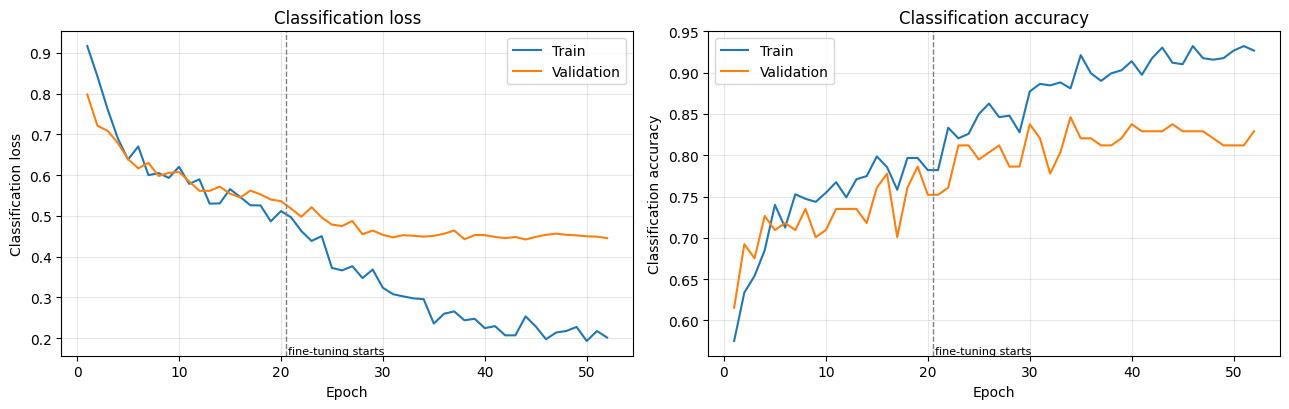

Epochs run (model 1): stage 1 = 20 | stage 2 = 32


In [ ]:
# Training curves for model 1 (loss and accuracy, train vs validation, both stages)
h1, h2 = histories[0]
H = {k: h1.history[k] + h2.history[k] for k in ['probs_loss', 'val_probs_loss', 'probs_accuracy', 'val_probs_accuracy']}
ep = np.arange(1, len(H['probs_loss']) + 1); split_at = len(h1.history['probs_loss']) + 0.5
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (tr, va, title) in zip(axes, [('probs_loss', 'val_probs_loss', 'Classification loss'), ('probs_accuracy', 'val_probs_accuracy', 'Classification accuracy')]):
    ax.plot(ep, H[tr], label='Train'); ax.plot(ep, H[va], label='Validation')
    ax.axvline(split_at, color='gray', ls='--', lw=1); ax.text(split_at + 0.2, ax.get_ylim()[0], 'fine-tuning starts', fontsize=8, va='bottom')
    ax.set(title=title, xlabel='Epoch', ylabel=title); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150); plt.show()
print('Epochs run (model 1): stage 1 =', len(h1.history['probs_loss']), '| stage 2 =', len(h2.history['probs_loss']))

## 7. Fix the decision rule on the VALIDATION set
Rule (chosen before looking at test):
1. Keep thresholds where validation malignant recall >= 0.70 **and** precision >= 0.70, take the one with the best macro F1.
2. If none qualify, among thresholds with malignant recall >= 0.60 take the best (malignant F1 + macro F1).

Caveat: the validation set has only 32 malignant images, so the threshold is noisy.

In [ ]:
pv_ens, _ = predict_all(models, x_val, tta=False)
experiments.append({'Experiment': f'C. Ensemble of {len(models)} models (argmax)', **fmt(compute_metrics(y_val, pv_ens.argmax(1)))})
pv_final, sv_final = predict_all(models, x_val, tta=USE_TTA)
experiments.append({'Experiment': 'D. + flip TTA (argmax)', **fmt(compute_metrics(y_val, pv_final.argmax(1)))})

grid = np.round(np.arange(0.05, 0.951, 0.01), 2); rows = []
for t in grid:
    pred = apply_rule(pv_final, t); m_ = compute_metrics(y_val, pred)
    _, _, f_, _ = precision_recall_fscore_support(y_val, pred, labels=[0, 1, 2], zero_division=0)
    rows.append({'t': t, **m_, 'mal_f1': f_[MAL]})
sweep = pd.DataFrame(rows)
feasible = sweep[(sweep.mal_recall >= 0.70) & (sweep.mal_precision >= 0.70)]
if len(feasible):
    best = feasible.sort_values(['macro_f1', 'mal_precision'], ascending=False).iloc[0]; how = 'meets both preferred malignant targets on validation'
else:
    pool = sweep[sweep.mal_recall >= 0.60]
    if len(pool) == 0: pool = sweep
    best = pool.assign(score=pool.mal_f1 + pool.macro_f1).sort_values('score', ascending=False).iloc[0]
    how = 'no threshold met both targets; chose best malignant F1 + macro F1 among those with recall >= 0.60'
THRESHOLD = float(best.t)
print(f'Chosen threshold = {THRESHOLD:.2f}  ({how})')
print({k: round(float(best[k]), 3) for k in ['accuracy', 'mal_recall', 'mal_precision', 'macro_f1']})
experiments.append({'Experiment': f'E. + malignant threshold {THRESHOLD:.2f} (tuned on val, so optimistic)',
                    **fmt(compute_metrics(y_val, apply_rule(pv_final, THRESHOLD)))})

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sweep.t, sweep.mal_recall, label='Malignant recall'); ax.plot(sweep.t, sweep.mal_precision, label='Malignant precision')
ax.plot(sweep.t, sweep.macro_f1, label='Macro F1'); ax.plot(sweep.t, sweep.accuracy, label='Accuracy', alpha=0.6)
ax.axvline(THRESHOLD, color='k', ls='--', label=f'chosen t = {THRESHOLD:.2f}'); ax.axhline(0.70, color='gray', ls=':', lw=1)
ax.set(title='Validation: effect of the malignant threshold', xlabel='Threshold on P(malignant)', ylabel='Metric'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/threshold_sweep_validation.png', dpi=150); plt.show()
exp_table = pd.DataFrame(experiments); exp_table.to_csv(f'{OUT_DIR}/experiment_log_validation.csv', index=False)
print('\nExperiment log (VALIDATION set only):'); display(exp_table)

NameError: name 'predict_all' is not defined

## 8. Final evaluation on the TEST split (run once)
Models, TTA, ensemble size and threshold are frozen. Test predictions are computed a single time and stored.

Test predictions computed once.


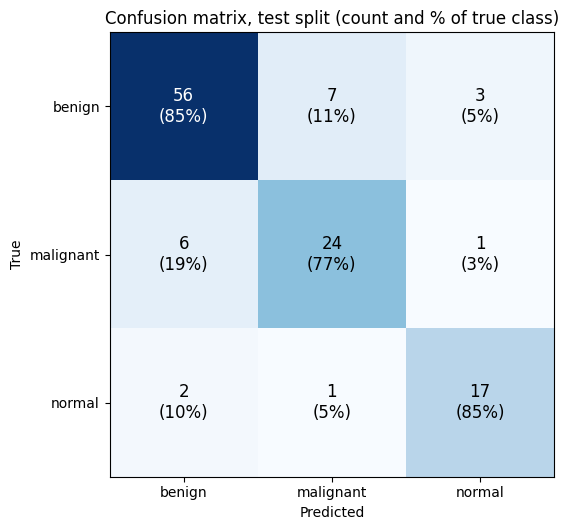

,Precision,Recall,F1,Support
benign,0.875,0.848,0.862,66
malignant,0.750,0.774,0.762,31
normal,0.810,0.850,0.829,20


Missed malignant: 7 of 31 | benign/normal flagged malignant: 8
Lesion segmentation Dice (benign+malignant test): mean 0.788, median 0.903
Normal test images with a predicted lesion area > 1%: 30%


In [ ]:
if 'TEST_PROBS' not in globals():
    TEST_PROBS, TEST_SEG = predict_all(models, x_test, tta=USE_TTA)
    print('Test predictions computed once.')
else:
    print('Test predictions already computed earlier; reusing them (no re-evaluation).')

y_pred = apply_rule(TEST_PROBS, THRESHOLD)
final = compute_metrics(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6.2, 5.4)); ax.imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})', ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
ax.set(xlabel='Predicted', ylabel='True', title='Confusion matrix, test split (count and % of true class)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix_test.png', dpi=150); plt.show()

p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2], zero_division=0)
per_class = pd.DataFrame({'Precision': p, 'Recall': r, 'F1': f, 'Support': s}, index=CLASS_NAMES).round(3)
per_class.to_csv(f'{OUT_DIR}/per_class_results_test.csv'); display(per_class)
print('Missed malignant:', int(((y_test == MAL) & (y_pred != MAL)).sum()), 'of', int((y_test == MAL).sum()),
      '| benign/normal flagged malignant:', int(((y_test != MAL) & (y_pred == MAL)).sum()))

# Segmentation quality of the predicted lesion mask (benign + malignant test images only)
def dice(a, b): return (2 * (a & b).sum() + 1e-6) / (a.sum() + b.sum() + 1e-6)
les = np.where(y_test != 2)[0]
d_scores = [dice(TEST_SEG[i, :, :, 0] > 0.5, m_test[i, :, :, 0] > 0) for i in les]
fp_rate = float(np.mean([(TEST_SEG[i, :, :, 0] > 0.5).mean() > 0.01 for i in np.where(y_test == 2)[0]]))
print(f'Lesion segmentation Dice (benign+malignant test): mean {np.mean(d_scores):.3f}, median {np.median(d_scores):.3f}')
print(f'Normal test images with a predicted lesion area > 1%: {fp_rate:.0%}')

In [ ]:
def status(metric, v):
    mand, pref = SOP[metric]
    tag = 'report' if mand is None else ('PASS' if v >= mand else 'FAIL')
    return f"{tag} / preferred {'PASS' if v >= pref else 'no'}"

ba = pd.DataFrame({'Day 2 baseline': {METRIC_LABELS[k]: BASELINE[k] for k in BASELINE},
                   'Final model':    {METRIC_LABELS[k]: round(float(final[k]), 3) for k in BASELINE}})
ba['Change'] = (ba['Final model'] - ba['Day 2 baseline']).round(3)
ba['SOP mandatory'] = [('report' if SOP[k][0] is None else f'>= {SOP[k][0]}') for k in BASELINE]
ba['SOP preferred'] = [f'>= {SOP[k][1]}' for k in BASELINE]
ba['Status (mandatory / preferred)'] = [status(k, final[k]) for k in BASELINE]
ba.to_csv(f'{OUT_DIR}/before_after_table.csv'); display(ba)

# Bootstrap 95% CI: how uncertain are the numbers with only 117 test images?
rng = np.random.default_rng(SPLIT_SEED); n = len(y_test); boots = []
for _ in range(2000):
    idx = rng.integers(0, n, n); boots.append(compute_metrics(y_test[idx], y_pred[idx]))
ci = pd.DataFrame({METRIC_LABELS[k]: [np.percentile([b[k] for b in boots], 2.5), np.percentile([b[k] for b in boots], 97.5)]
                   for k in BASELINE}, index=['95% CI low', '95% CI high']).T.round(3)
ci.insert(0, 'Point estimate', [round(float(final[k]), 3) for k in BASELINE])
print('Bootstrap 95% confidence intervals (test, 2000 resamples):'); display(ci); ci.to_csv(f'{OUT_DIR}/test_metrics_bootstrap_ci.csv')

,Day 2 baseline,Final model,Change,SOP mandatory,SOP preferred,Status (mandatory / preferred)
Accuracy,0.598,0.829,0.231,>= 0.62,>= 0.7,PASS / preferred PASS
Malignant recall,0.548,0.774,0.226,>= 0.6,>= 0.7,PASS / preferred PASS
Macro F1,0.546,0.818,0.272,>= 0.58,>= 0.65,PASS / preferred PASS
Malignant precision,0.607,0.750,0.143,report,>= 0.7,report / preferred PASS


Bootstrap 95% confidence intervals (test, 2000 resamples):


,Point estimate,95% CI low,95% CI high
Accuracy,0.829,0.752,0.897
Malignant recall,0.774,0.611,0.912
Macro F1,0.818,0.734,0.889
Malignant precision,0.750,0.594,0.895


## 9. Explainability: Grad-CAM + predicted lesion mask (at least 6 images, including errors)
Row 1: original with the expert lesion outline (green, for comparison only). Row 2: Grad-CAM of the final decision class (model 1). Row 3: lesion mask predicted by the Attention U-Net decoder (ensemble). Attention on the lesion is a good sign; attention on borders, text or shadow artifacts would be a warning.

Grad-CAM layer: top_activation
Showing 7 images, of which 3 are misclassified.


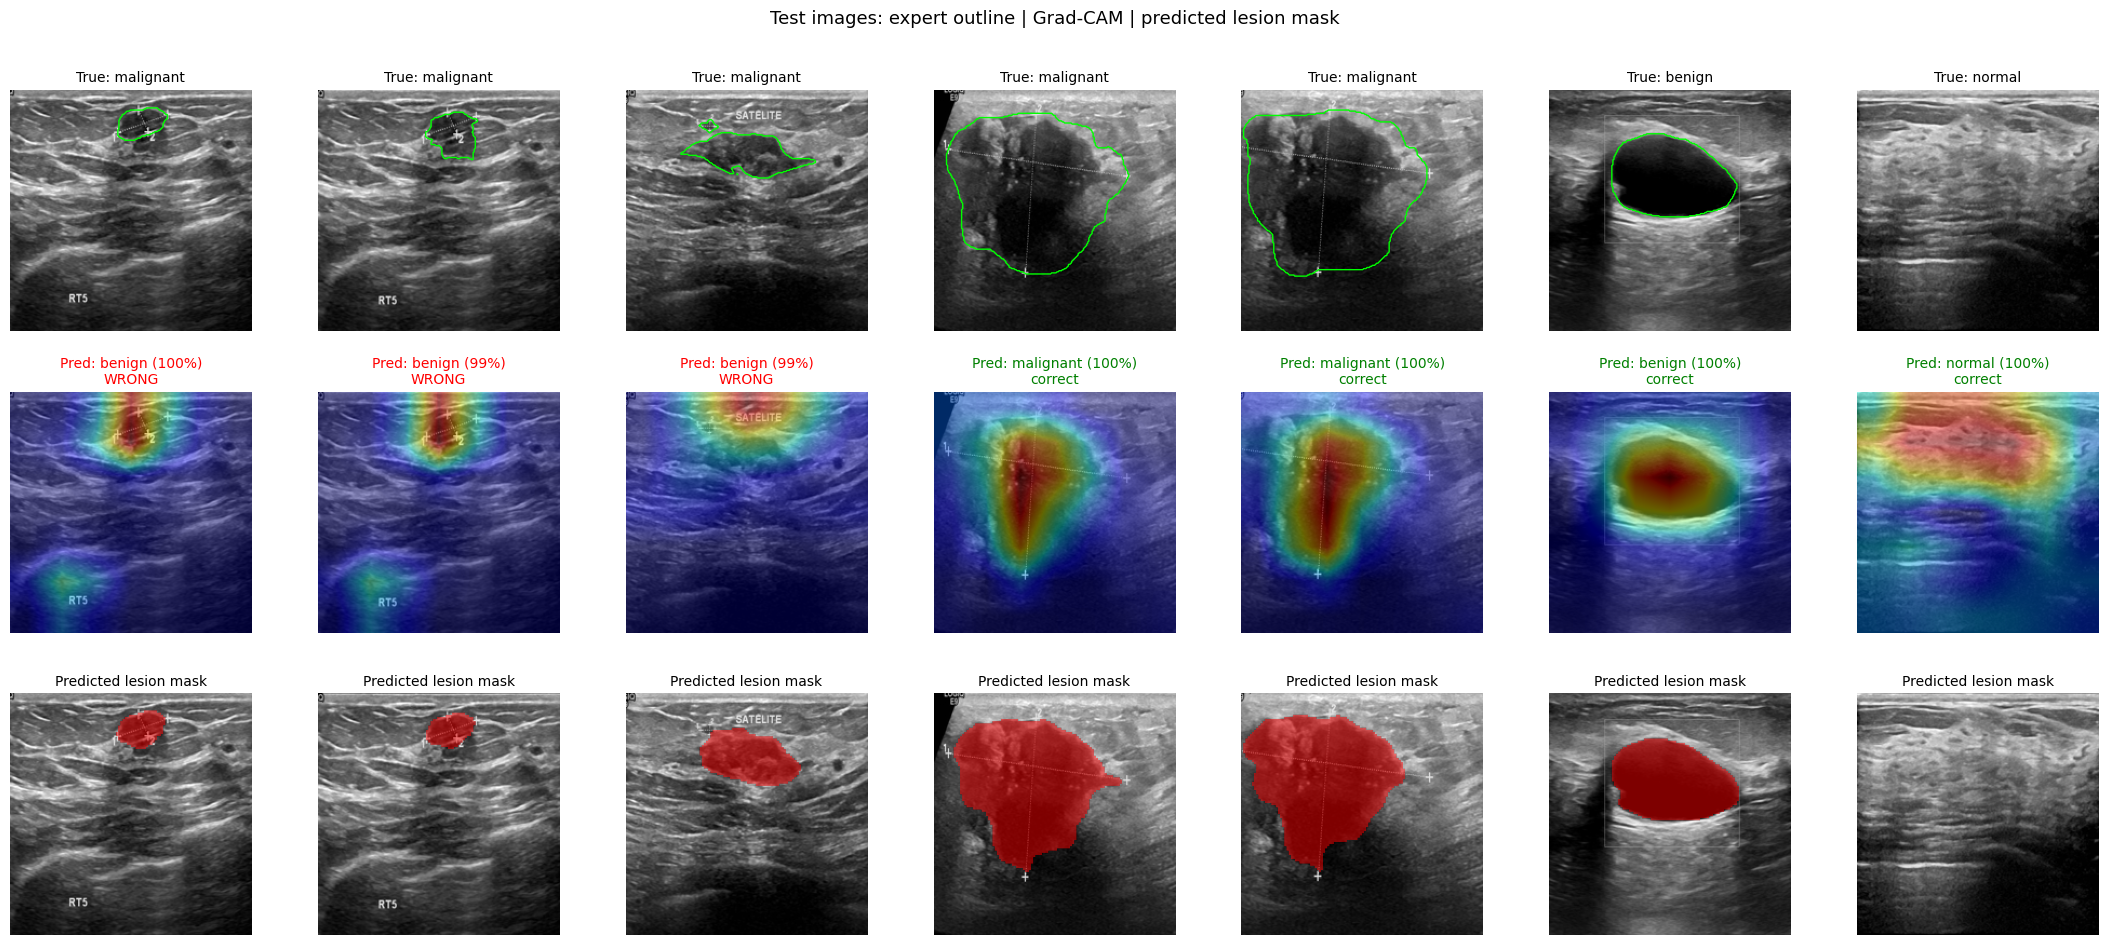

In [ ]:
gm = models[0]
conv_name = next(l.name for l in reversed(gm.layers) if getattr(l, 'output', None) is not None and len(l.output.shape) == 4 and l.name.startswith('top_'))
grad_model = keras.Model(gm.inputs, [gm.get_layer(conv_name).output, gm.get_layer('logits').output])
print('Grad-CAM layer:', conv_name)

def gradcam(img_gray_uint8, class_idx):
    x = to_rgb255(img_gray_uint8[None])
    with tf.GradientTape() as tape:
        conv, lg = grad_model(x, training=False)
        score = lg[:, class_idx]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * w, axis=-1)); cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()

conf = TEST_PROBS[np.arange(len(y_test)), y_pred]
wrong = np.where(y_pred != y_test)[0]
prio = lambda i: 0 if (y_test[i] == MAL) else (1 if y_pred[i] == MAL else 2)   # missed malignant first, then false alarms
wrong = sorted(wrong, key=lambda i: (prio(i), -conf[i]))[:3]
chosen = list(wrong)
for cls, k in [(MAL, 2), (0, 1), (2, 1)]:
    ok = [i for i in np.where((y_test == cls) & (y_pred == cls))[0] if i not in chosen]
    chosen += sorted(ok, key=lambda i: -conf[i])[:k]
if len(chosen) < 6:
    chosen += [i for i in np.argsort(-conf) if i not in chosen][:6 - len(chosen)]
n_wrong_shown = int(sum(y_pred[i] != y_test[i] for i in chosen))
print(f'Showing {len(chosen)} images, of which {n_wrong_shown} are misclassified.')
if n_wrong_shown < 2: print('WARNING: fewer than 2 errors on test; SOP asks for at least 2 wrong examples. Report this honestly.')

fig, axes = plt.subplots(3, len(chosen), figsize=(3.1 * len(chosen), 9.6))
for c, i in enumerate(chosen):
    img = x_test[i, :, :, 0]; cam = gradcam(x_test[i], int(y_pred[i])); ok = y_pred[i] == y_test[i]
    axes[0, c].imshow(img, cmap='gray')
    if m_test[i].max() > 0: axes[0, c].contour(m_test[i, :, :, 0], levels=[0.5], colors='lime', linewidths=1)
    axes[0, c].set_title(f'True: {CLASS_NAMES[y_test[i]]}', fontsize=10)
    axes[1, c].imshow(img, cmap='gray'); axes[1, c].imshow(cam, cmap='jet', alpha=0.40, vmin=0, vmax=1)
    axes[1, c].set_title(f'Pred: {CLASS_NAMES[y_pred[i]]} ({conf[i]:.0%})\n' + ('correct' if ok else 'WRONG'), fontsize=10, color='green' if ok else 'red')
    axes[2, c].imshow(img, cmap='gray'); axes[2, c].imshow(np.ma.masked_where(TEST_SEG[i, :, :, 0] <= 0.5, TEST_SEG[i, :, :, 0] > 0.5), cmap='autumn', alpha=0.5)
    axes[2, c].set_title('Predicted lesion mask', fontsize=10)
    for r_ in range(3): axes[r_, c].axis('off')
plt.suptitle('Test images: expert outline | Grad-CAM | predicted lesion mask', fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.subplots_adjust(hspace=0.25)
plt.savefig(f'{OUT_DIR}/gradcam_test.png', dpi=140); plt.show()

## 10. Summary for the deck and the submission form

In [ ]:
print('=' * 66); print('FINAL TEST RESULTS vs HOSPITAL SOP (official test split, n = %d)' % len(y_test)); print('=' * 66)
for k in BASELINE:
    mand, pref = SOP[k]
    print(f'{METRIC_LABELS[k]:<20} {final[k]:.3f}   (Day 2: {BASELINE[k]:.3f})   mandatory: '
          f"{'report only' if mand is None else ('PASS' if final[k] >= mand else 'FAIL') + f' (>= {mand})'}   preferred: "
          f"{'PASS' if final[k] >= pref else 'not met'} (>= {pref})")
print('\nDecision rule fixed on validation: P(malignant) >= %.2f -> malignant; otherwise best of benign / normal' % THRESHOLD)
print('Ensemble of', len(models), 'models | flip TTA:', USE_TTA, '| pretrained:', PRETRAINED, '| quick test:', QUICK_TEST)
if QUICK_TEST: print('QUICK_TEST is ON: these numbers are NOT valid results.')

results = {'threshold': THRESHOLD, 'test_metrics': {k: float(v) for k, v in final.items()}, 'baseline': BASELINE,
           'confusion_matrix': cm.tolist(), 'class_names': CLASS_NAMES, 'quick_test': QUICK_TEST,
           'seg_dice_mean': float(np.mean(d_scores)),
           'config': dict(IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS_HEAD=EPOCHS_HEAD, EPOCHS_FT=EPOCHS_FT, FT_LAYERS=FT_LAYERS,
                          LR_HEAD=LR_HEAD, LR_FT=LR_FT, SEG_WEIGHT=SEG_WEIGHT, MODEL_SEEDS=MODEL_SEEDS, SPLIT_SEED=SPLIT_SEED, USE_TTA=USE_TTA)}
json.dump(results, open(f'{OUT_DIR}/results.json', 'w'), indent=2)

FINAL TEST RESULTS vs HOSPITAL SOP (official test split, n = 117)
Accuracy             0.829   (Day 2: 0.598)   mandatory: PASS (>= 0.62)   preferred: PASS (>= 0.7)
Malignant recall     0.774   (Day 2: 0.548)   mandatory: PASS (>= 0.6)   preferred: PASS (>= 0.7)
Macro F1             0.818   (Day 2: 0.546)   mandatory: PASS (>= 0.58)   preferred: PASS (>= 0.65)
Malignant precision  0.750   (Day 2: 0.607)   mandatory: report only   preferred: PASS (>= 0.7)

Decision rule fixed on validation: P(malignant) >= 0.52 -> malignant; otherwise best of benign / normal
Ensemble of 3 models | flip TTA: True | pretrained: True | quick test: False


## 12. Limitations and next steps (copy into the deck)
* **Small test set.** 117 test images, 31 malignant: one malignant case moves recall by about 3 points. Read the bootstrap confidence intervals in section 8, not only the point estimates.
* **Threshold tuned on 32 malignant validation images.** It is noisy. A larger, multi-hospital validation set is needed before clinical use.
* **Public single-source dataset, image-level split.** BUSI has no patient IDs; near-duplicates or same-patient images can make results optimistic.
* **Domain shift.** RS Beeonic has 3 ultrasound machines from 2 brands. Re-validate per machine on local data before going live.
* **Triage, not diagnosis.** The AI only re-orders the worklist; a radiologist reads every image, and a false *normal* must never remove a case from the queue. Triage times in the API are proposed pilot targets, not hospital policy.
* **Regulatory.** No Kemenkes distribution permit yet (typically 6 to 12 months); use the API in shadow mode for evaluation only.
* **Next steps:** shadow-mode pilot on local data, recalibrate the threshold locally, monitor override rate and malignant precision monthly, add authentication/HTTPS/audit logging for production.